To implement a complete Machine Learning project involving data collection,data cleaning, feature engineering, model training, and mdel evaluation using a real world dataset

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report

data = pd.read_csv("data.csv")
print(data.shape)
print(data.columns)
data.head()

#check datatypes:
print(data.dtypes)

#get basic statistical information:
print(data.describe())

#check missing values
print(data.isnull().sum())

#check duplicate records
print("\n",data.duplicated().sum())

#data cleaning
data["StudyHours"] = data["StudyHours"].fillna(data["StudyHours"].mean())
data["Attendance"] = data["Attendance"].fillna(data["Attendance"].mean())
data["PreviousMarks"] = data["PreviousMarks"].fillna(data["PreviousMarks"].mean())
data["AssignmentScore"] = data["AssignmentScore"].fillna(data["AssignmentScore"].mean())
print(data.isnull().sum())

(16, 5)
Index(['StudyHours', 'Attendance', 'PreviousMarks', 'AssignmentScore',
       'Result'],
      dtype='object')
StudyHours         float64
Attendance         float64
PreviousMarks      float64
AssignmentScore    float64
Result               int64
dtype: object
       StudyHours  Attendance  PreviousMarks  AssignmentScore     Result
count   15.000000   15.000000      16.000000        16.000000  16.000000
mean     5.540000   72.133333      66.806250        75.500000   0.812500
std      2.786908    8.762882      17.170303        15.074305   0.403113
min      1.700000   57.000000      46.700000        52.200000   0.000000
25%      2.850000   65.550000      50.800000        63.600000   1.000000
50%      6.300000   73.600000      63.600000        75.600000   1.000000
75%      7.800000   77.600000      80.750000        88.650000   1.000000
max      9.300000   88.800000      93.300000        96.500000   1.000000
StudyHours         1
Attendance         1
PreviousMarks      0
AssignmentSc

0


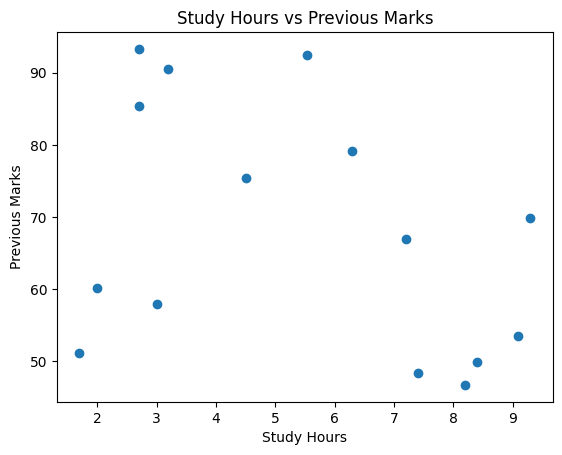

0     73.57
1     61.33
2     65.10
3     81.90
4     75.24
5     87.50
6     68.54
7     70.13
8     80.82
9     72.79
10    75.34
11    63.26
12    59.63
13    76.01
14    59.94
Name: PerformanceScore, dtype: float64
[1 0 0]
    Actual  Predicted
9        1          1
11       1          0
0        1          0
Accuracy: 0.3333333333333333
Precision: 1.0


In [3]:
data = data.drop_duplicates()
print(data.duplicated().sum())

plt.scatter(data["StudyHours"],data["PreviousMarks"])
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.title("Study Hours vs Previous Marks")
plt.show()

#feature engineering
data["PerformanceScore"] = (0.4*data["PreviousMarks"]+0.3*data["Attendance"]+0.3*data["AssignmentScore"])
print(data["PerformanceScore"])

X=data[["StudyHours","Attendance","PreviousMarks","AssignmentScore","PerformanceScore"]]
Y=data["Result"]

#splitting of dataset
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size = 0.2,random_state=42)

model = DecisionTreeClassifier(max_depth = 3,random_state = 42)
model.fit(X_train,Y_train)
Y_pred=model.predict(X_test)
print(Y_pred)
result = pd.DataFrame({"Actual":Y_test,"Predicted":Y_pred})
print(result)

accuracy = accuracy_score(Y_test,Y_pred)
print("Accuracy:",accuracy)
precision = precision_score(Y_test,Y_pred)
print("Precision:",precision)
